# Compression de données par ACP (Langage R)
*Formation Machine Learning, BI105, Philippe BONNY@2020*

<img src="https://drive.google.com/thumbnail?id=1N98A0sJIPXym5OzZ5Gs3QgVJtaqX2Wqb&sz=w1200">

## UTILITAIRES

### Ressources de calcul

In [0]:
%python
# VM
vm="Azure Standard DS3_v2 (4 cores, 14Gb)"
print(f"VM : {vm}")

# Databricks runtime version
import os
print("DATABRICKS_RUNTIME_VERSION: (FM)",os.environ.get('DATABRICKS_RUNTIME_VERSION',None))

#Python version
!python -V 

# Désactivation MlFlow
import mlflow
mlflow.autolog(disable=True)
print("MlFlow désactivé")

VM : Azure Standard DS3_v2 (4 cores, 14Gb)
DATABRICKS_RUNTIME_VERSION: (FM) 17.3
Python 3.12.3
MlFlow désactivé


### Librairies

- installation <br>
*Rq : procesus long ...*

In [0]:
require(devtools)
install.packages("FactoMineR")
install.packages("factoextra")
install.packages("kernlab")

* installing *binary* package ‘FactoMineR’ ...
* DONE (FactoMineR)
* installing *binary* package ‘factoextra’ ...
* DONE (factoextra)
* installing *binary* package ‘kernlab’ ...
* DONE (kernlab)
Installing package into ‘/local_disk0/.ephemeral_nfs/envs/rEnv-007b1dee-e6f5-4b54-83e4-26e8f69764ad’
(as ‘lib’ is unspecified)
trying URL 'https://databricks.packagemanager.posit.co/cran/__linux__/noble/2025-03-20/src/contrib/FactoMineR_2.11.tar.gz'
Content type 'binary/octet-stream' length 3798550 bytes (3.6 MB)
downloaded 3.6 MB


The downloaded source packages are in
	‘/tmp/Rtmp08l8wM/downloaded_packages’
Installing package into ‘/local_disk0/.ephemeral_nfs/envs/rEnv-007b1dee-e6f5-4b54-83e4-26e8f69764ad’
(as ‘lib’ is unspecified)
trying URL 'https://databricks.packagemanager.posit.co/cran/__linux__/noble/2025-03-20/src/contrib/factoextra_1.0.7.tar.gz'
Content type 'binary/octet-stream' length 420118 bytes (410 KB)
downloaded 410 KB


The downloaded source packages are in
	‘/tmp/Rtmp08l8wM/do

- chargement

In [0]:
library(FactoMineR)   # analyse exploratoire multidimensionnelle de données 
library(factoextra)   # visualisation d'analyse multidim.
library(caret)        # machine learning
library(ggplot2)      # graphique
library(MASS)         # contient les données

Loading required package: ggplot2
Welcome! Want to learn more? See two factoextra-related books at https://goo.gl/ve3WBa
Loading required package: lattice
Loading required package: survival

Attaching package: ‘survival’

The following object is masked from ‘package:caret’:

    cluster


## DATA

In [0]:
# Chargement
file <- './wine.data'
df_wine <- read.csv(file, header = FALSE)

# Affectation des noms de colonnes
colnames(df_wine) <-  c(
    'Class label', 'Alcohol', 'Malic acid', 'Ash',
    'Alcalinity of ash', 'Magnesium', 'Total phenols',
    'Flavanoids', 'Nonflavanoid phenols', 'Proanthocyanins',
    'Color intensity', 'Hue',
    'OD280/OD315 of diluted wines', 'Proline')

# Partitionnement
X <- df_wine[-1]
y <- df_wine[1]

indx_split <- sample(1:nrow(df_wine), size=0.2*nrow(df_wine))
X_test <- X[indx_split, ]
y_test <- y[indx_split, ]
X_train <- X[-indx_split, ]
y_train <- y[-indx_split, ]

cat('X_train dim : ', dim(X_train))
cat('\nX_test dim : ', dim(X_test))

X_train dim :  143 13
X_test dim :  35 13

## COMPRESSION LINÉAIRE PAR ACP

- approche "non supervisée" de la compression (cf analyse factorielle discriminante qui quant à elle est "supervisée")
- Adapté à partir de : http://www.sthda.com/french/articles/38-methodes-des-composantes-principales-dans-r-guide-pratique/73-acp-analyse-en-composantes-principales-avec-r-l-essentiel/

### Variance expliquée
- Analyse de la variance expliquée en fonction des différentes composantes principales <br>
*Rq : par défaut les données sont standardisées dans PCA*

In [0]:
# instanciation d'un ACP du package FactoMiner
X_train_pca <- PCA(X_train, graph = FALSE)
X_train_pca

**Results for the Principal Component Analysis (PCA)**
The analysis was performed on 143 individuals, described by 13 variables
*The results are available in the following objects:

   name               description                          
1  "$eig"             "eigenvalues"                        
2  "$var"             "results for the variables"          
3  "$var$coord"       "coord. for the variables"           
4  "$var$cor"         "correlations variables - dimensions"
5  "$var$cos2"        "cos2 for the variables"             
6  "$var$contrib"     "contributions of the variables"     
7  "$ind"             "results for the individuals"        
8  "$ind$coord"       "coord. for the individuals"         
9  "$ind$cos2"        "cos2 for the individuals"           
10 "$ind$contrib"     "contributions of the individuals"   
11 "$call"            "summary statistics"                 
12 "$call$centre"     "mean of the variables"              
13 "$call$ecart.type" "standard error 

In [0]:
# affichage des valeurs propres associées aux axes principaux
eig.val <- get_eigenvalue(X_train_pca)
eig.val

       eigenvalue variance.percent cumulative.variance.percent
Dim.1  4.85198152       37.3229348                    37.32293
Dim.2  2.48721293       19.1324071                    56.45534
Dim.3  1.34895227       10.3765560                    66.83190
Dim.4  1.01922659        7.8402046                    74.67210
Dim.5  0.83411215        6.4162473                    81.08835
Dim.6  0.65726032        5.0558486                    86.14420
Dim.7  0.53885325        4.1450250                    90.28922
Dim.8  0.32685607        2.5142775                    92.80350
Dim.9  0.27220072        2.0938517                    94.89735
Dim.10 0.22705499        1.7465768                    96.64393
Dim.11 0.20542879        1.5802215                    98.22415
Dim.12 0.14669679        1.1284369                    99.35259
Dim.13 0.08416359        0.6474123                   100.00000

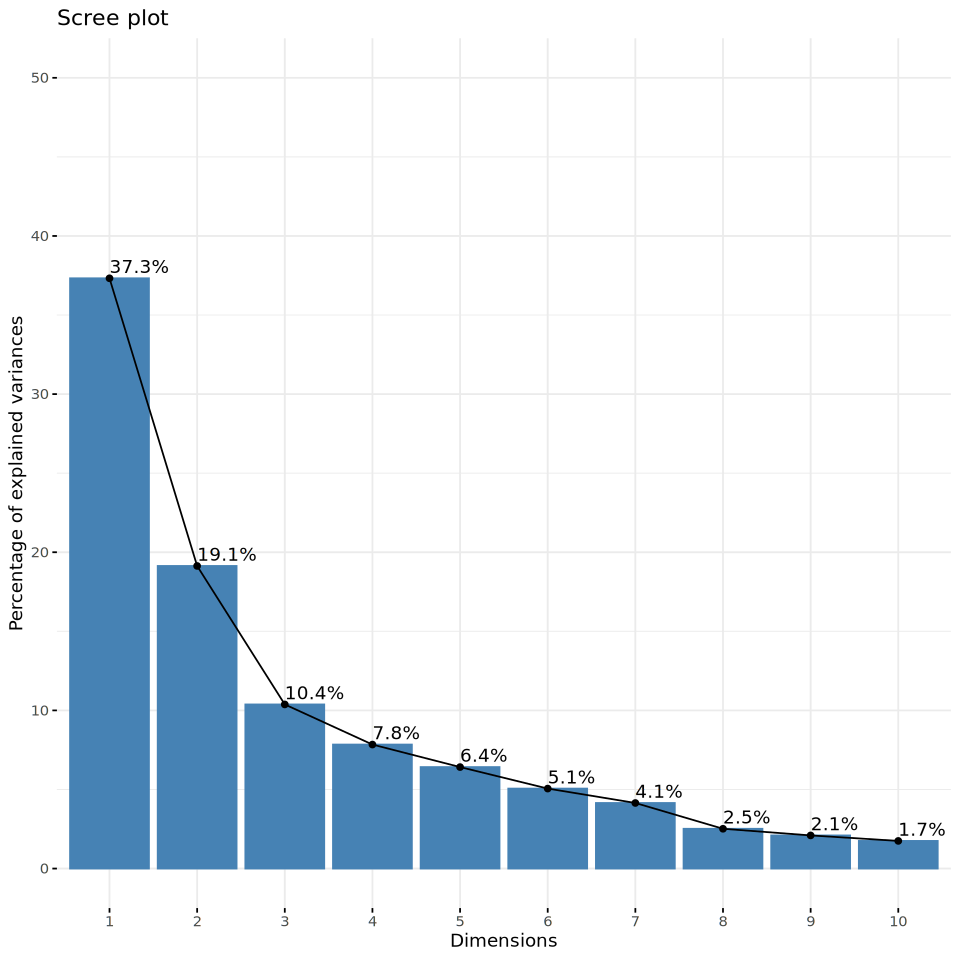

In [0]:
# ibid - graphiquement
options(repr.plot.width=1000, repr.plot.height=500)
fviz_eig(X_train_pca, addlabels = TRUE, ylim = c(0, 50))

> On constate que la première composante explique environ 40% de la variance totale du jeu de donnée.

### Application d'une ACP à 2 composantes

In [0]:
# Création du pipeline
preProc <- preProcess(X_train,method=c("scale","pca"),pcaComp=2)

# Application du modèle
X_train_pca <- predict(preProc, X_train)
X_test_pca <- predict(preProc, X_test)

In [0]:
# Affichage des données projetées sur les 2 axes ACP
options(repr.plot.width=7, repr.plot.height=4)
ggplot(cbind(X_train_pca, cat=as.factor(y_train)), 
           aes(x=PC1, y=PC2, color=cat, shape=cat)) +
       geom_point()

In [0]:
# Création d'un modèle prédictif lineaire ex svmlinear
Train = cbind(X_train_pca, class = as.factor(y_train))
Test <- cbind(X_test_pca, class = as.factor(y_test))
mod_fit <- train(class ~ .,  data=Train, method="svmLinear")

# Affichage des performances
test_pred <- predict(mod_fit, Test)
postResample(test_pred, Test$class)
#confusionMatrix(test_pred, Test$class))

 Accuracy     Kappa 
0.9142857 0.8653846 